# Evaluación Empírica de Redes Neuronales Recurrentes (GRU) frente a Baselines Clásicos para la Predicción Direccional de SPY a 5 Días
## Validación Walk-Forward, Calibración de Brier y Mitigación Fiduciaria en AlphaTQ

**Maestría en Inteligencia Artificial — Universidad de Palermo (UP)**  
**Asignatura:** Redes Neuronales y Deep Learning  
**Equipo de Investigación (Grupo N° 4):**  
- **Diego Diamnti
- **Melisa Maldonado
- **Diego Weber

**Fecha:** Octubre 2026 | **Semilla Determinística:** 42  
**Código Fuente:** `Deep_Market_Representation_Learning_Lab_AlphaTQ_Inspired (1).ipynb`

> **Versión corregida — registro de cambios**
> 1. `log_loss(eps=...)` reemplazado por recorte manual: el argumento `eps` fue eliminado en scikit-learn ≥ 1.5 y el notebook no corría.
> 2. **Regresión Logística entrenada con datos escalados** (antes: train sin escalar y test escalado, lo que invalidaba la comparación con la GRU).
> 3. Purga de `HORIZON` muestras entre train y validación interna del EarlyStopping.
> 4. Simulación económica con el **retorno real del día siguiente**, Buy & Hold real y **costos de transacción** (antes se usaba un promedio del retorno futuro a 5 días y los costos no se aplicaban).
> 5. Sizing: se distingue el **Half-Kelly real** ($p - 0.5$) de la regla lineal $(p-0.5)/0.2$, que equivale a 2,5 veces Kelly completo.
> 6. Cantidad de features corregida a **78** y promedio **ponderado** por tamaño de test agregado a la tabla resumen.
> 7. Nueva sección 14.B: **bootstrap por bloques** para la significancia de las diferencias.
> 8. Conclusiones calculadas desde los resultados; se eliminaron las cifras escritas a mano.
> 9. Fold 4 hasta el último dato disponible y determinismo de TensorFlow activado.


## 0. Contextualización Institucional y Pregunta de Investigación

### ¿Qué es AlphaTQ?
**AlphaTQ** es un framework de trading algorítmico, simulación cuantitativa y gestión de riesgo fiduciario desarrollado por los autores (`C:\Users\diego\excel_rtd`). El sistema opera bajo una arquitectura desacoplada en 6 capas funcionales:
1. **Capa 0 (Ingesta):** Limpieza, normalización y cálculo de variables point-in-time sin leakage.
2. **Capa 1 (Perception Engine):** Redes neuronales y clasificadores que operan exclusivamente como sensores de contexto y régimen macroeconómico.
3. **Capa 2 (Risk Guardian):** Detección de anomalías multidimensionales (distancias de Mahalanobis y umbrales de volatilidad) que imponen frenos de emergencia.
4. **Capa 3 (Decision Brain):** Bandidos multi-brazo (Thompson Sampling) y heurísticas que seleccionan la estrategia óptima según el régimen de mercado.
5. **Capa 4 (Portfolio Sizing):** Asignación de capital basada en Half-Kelly continuo modulado por la probabilidad estimada y anclaje estricto de volatilidad.
6. **Capa 5 (Smart Execution):** Algoritmos de ejecución institucional (VWAP, TWAP, Almgren-Chriss) para minimizar el impacto de mercado.

> **Principio Fiduciario Cardinal:** En sistemas institucionales, las redes neuronales profundas **jamás deben emitir órdenes directas de compra/venta al mercado** debido a su vulnerabilidad a rupturas de régimen no estacionarias. Su rol se restringe a la **Capa 1 de Percepción**, informando probabilidades y estados para que las capas determinísticas gestionen el capital de forma prudente.

---

### Pregunta de Investigación Delimitada (Feedback Docente)
Atendiendo a las recomendaciones metodológicas del cuerpo docente para evitar la dispersión de objetivos y enfocar el laboratorio en una pregunta científica única, comprobable y rigurosa, este trabajo responde:

> **¿Puede una red neuronal recurrente (GRU) predecir el signo del retorno acumulado a 5 días del S&P 500 (SPY) a partir de ventanas temporales de $N$ días superando a una Regresión Logística y a una Línea de Base Ingenua (Naive), evaluada bajo validación temporal Walk-Forward y calibración medida con el Puntaje de Brier?**

### Hipótesis y Criterios de Evaluación
- **Variable Objetivo ($y_t$):** Signo del retorno acumulado forward a 5 ruedas de negociación ($H=5$):
  $$y_t = \mathbb{I}\left(\frac{P_{t+5} - P_t}{P_t} > 0\right) \in \{0, 1\}$$
- **Modelos Comparados:**
  1. **Línea de Base Ingenua (Naive Baseline):** Estimador empírico inercial basado en el sesgo alcista histórico del conjunto de entrenamiento (Prior de clase: $\hat{p} = \bar{y}_{train}$).
  2. **Regresión Logística:** Modelo lineal tabular regularizado (L2 Ridge) entrenado sobre las variables contemporáneas.
  3. **Deep Learning Recurrente (GRU):** Red compacta con compuertas recurrentes, inyección de ruido estocástico contra sobreajuste y regularización L2.
- **Protocolo de Validación:** Validación temporal **Walk-Forward multi-fold** con ventanas expansivas, asegurando purga contra leakage y ajuste de escaladores exclusivamente con datos de entrenamiento.
- **Métrica Reina de Calibración:** **Puntaje de Brier (Brier Score)** y **Brier Skill Score (BSS)**, complementados con AUC-ROC y Accuracy.

In [1]:
# ============================================================
# 1. Instalación de Dependencias
# ============================================================
!pip -q install yfinance scikit-learn pandas numpy matplotlib seaborn tensorflow scipy

In [2]:
# ============================================================
# 2. Imports y Configuración de Reproducibilidad
# ============================================================
import os, random, warnings, math, json, sys
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, brier_score_loss,
    log_loss, confusion_matrix
)
from sklearn.calibration import calibration_curve

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, regularizers

from scipy.stats import spearmanr

SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
# [FIX] Operaciones deterministas para que la semilla 42 reproduzca los mismos resultados
try:
    tf.config.experimental.enable_op_determinism()
except Exception as e:
    print("Determinismo de TF no disponible:", e)

print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

Python: 3.13.16
TensorFlow: 2.21.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 3. Parámetros del Laboratorio y Período Común

### Auditoría Temporal de Tickers (Feedback Docente)
Un error metodológico frecuente en finanzas es asumir fechas de inicio arbitrarias (por ejemplo, 2005) sin auditar las fechas reales de lanzamiento al mercado (*IPO*) de cada instrumento.
- **USO (United States Oil Fund):** Inició cotización pública el **10 de abril de 2006**.
- **HYG (iShares iBoxx $ High Yield Corporate Bond):** Inició cotización el **11 de abril de 2007**.

Para garantizar un período temporal común riguroso, sin valores faltantes, sin imputaciones artificiales y sin *survivorship bias*, el universo común inicia formalmente en **Mayo de 2007** (`START = '2007-05-01'`).

In [3]:
# ============================================================
# 3. Parámetros del Experimento y Universo Común
# ============================================================
TARGET = "SPY"

# Universo multi-activo macrofinanciero:
# Renta variable (SPY, QQQ, IWM), Bonos soberanos (TLT), Oro (GLD),
# Petróleo (USO), Crédito de alto rendimiento (HYG), y Sectores (XLE, XLK)
CONTEXT = [
    "SPY", "QQQ", "IWM", "TLT", "GLD", "USO", "HYG", "XLE", "XLK"
]

TICKERS = sorted(set([TARGET] + CONTEXT))
MACRO_VOL_TICKER = "^VIX"

# Período común estricto (HYG y USO cotizan plenamente desde Mayo 2007)
START = "2007-05-01"
END = None

# Parámetros del problema delimitado:
HORIZON = 5    # Retorno acumulado a 5 ruedas hábiles: R_{t -> t+5}
LOOKBACK = 20  # Ventana temporal N = 20 días (~1 mes bursátil)
EMBED_DIM = 16 # Dimensión latente intermedia

TRANSACTION_COST_BPS = 5

print("Target:", TARGET)
print("Context Tickers:", TICKERS)
print("Macro Volatility Ticker:", MACRO_VOL_TICKER)
print(f"Período común: {START} a la fecha | Lookback N = {LOOKBACK} | Horizonte H = {HORIZON}")

Target: SPY
Context Tickers: ['GLD', 'HYG', 'IWM', 'QQQ', 'SPY', 'TLT', 'USO', 'XLE', 'XLK']
Macro Volatility Ticker: ^VIX
Período común: 2007-05-01 a la fecha | Lookback N = 20 | Horizonte H = 5


## 4. Descarga de Datos

Los datos se descargan mediante `yfinance` en modo ajustado por dividendos y splits (`auto_adjust=True`). Se extrae de forma aislada el índice sintético de volatilidad implícita `^VIX`, el cual carece de volumen transaccional directo.

In [4]:
# ============================================================
# 4. Descarga Automatizada y Verificación de Cobertura
# ============================================================
raw = yf.download(
    TICKERS,
    start=START,
    end=END,
    auto_adjust=True,
    progress=False,
    group_by="column"
)

raw_vix = yf.download(
    MACRO_VOL_TICKER,
    start=START,
    end=END,
    auto_adjust=True,
    progress=False
)

print("Market Data Shape:", raw.shape)
print("VIX Data Shape:", raw_vix.shape)
print(f"Rango temporal cubierto: {raw.index.min().date()} -> {raw.index.max().date()}")
raw.tail()

Market Data Shape: (4893, 45)
VIX Data Shape: (4895, 5)
Rango temporal cubierto: 2007-05-01 -> 2026-10-09


Price            Close                                                 \
Ticker             GLD        HYG         IWM         QQQ         SPY   
Date                                                                    
2026-10-05  379.549988  76.980003  283.380005  756.200012  774.830017   
2026-10-06  382.269989  77.269997  281.339996  759.659973  779.090027   
2026-10-07  375.880005  77.180000  277.700012  757.729980  777.219971   
2026-10-08  378.619995  77.139999  277.570007  747.580017  773.929993   
2026-10-09  384.329987  77.105003  277.920013  748.919983  775.849976   

Price                                                           High  ...  \
Ticker            TLT         USO        XLE         XLK         GLD  ...   
Date                                                                  ...   
2026-10-05  77.110001  143.990005  63.450001  200.929993  380.779999  ...   
2026-10-06  77.279999  144.910004  63.750000  202.000000  383.570007  ...   
2026-10-07  77.150002  143.910004  63.360001  201.389999  378.250000  ...   
2026-10-08  77.870003  147.580002  65.239998  197.779999  379.880005  ...   
2026-10-09  77.669998  147.529999  65.470001  197.550003  384.380005  ...   

Price             Open   Volume                                          \
Ticker             XLK      GLD       HYG       IWM       QQQ       SPY   
Date                                                                      
2026-10-05  200.270004  4289400  39142800  22725800  25603200  44840200   
2026-10-06  202.479996  7506100  47352500  21814100  26513600  36054300   
2026-10-07  200.279999  7216600  59309100  24846800  25467900  30989200   
2026-10-08  199.750000  9669200  44872800  35685600  49470700  40351800   
2026-10-09  199.399994  1630070   1793503   2522976   4216977   2774459   

Price                                             
Ticker           TLT      USO       XLE      XLK  
Date                                              
2026-10-05  49106700  3558000  29430100  6587400  
2026-10-06  31085900  3439600  27824500  6124000  
2026-10-07  40200000  3086400  27139200  6326200  
2026-10-08  49379100  6000200  51290700  9130400  
2026-10-09   3267952   573435   3282831  1086774  

[5 rows x 45 columns]

In [5]:
# ============================================================
# 5. Normalización y Alineación de Series
# ============================================================
def get_field(df, field, ticker):
    if isinstance(df.columns, pd.MultiIndex):
        if (field, ticker) in df.columns:
            return df[(field, ticker)]
        if (ticker, field) in df.columns:
            return df[(ticker, field)]
    if field in df.columns:
        return df[field]
    raise KeyError((field, ticker))

prices = pd.DataFrame(index=raw.index)

for t in TICKERS:
    prices[f"{t}_close"] = get_field(raw, "Close", t)
    prices[f"{t}_volume"] = get_field(raw, "Volume", t)

prices = prices.sort_index()

# Extracción robusta de Close del VIX y alineación
if isinstance(raw_vix.columns, pd.MultiIndex):
    vix_close = raw_vix["Close"].iloc[:, 0]
elif "Close" in raw_vix.columns:
    vix_close = raw_vix["Close"]
else:
    vix_close = raw_vix.iloc[:, 0]

vix_series = vix_close.reindex(prices.index).ffill()

print("Matriz de precios normalizada:", prices.shape)
print("Serie de VIX alineada:", len(vix_series))
prices.head()

Matriz de precios normalizada: (4893, 18)
Serie de VIX alineada: 4893


,GLD_close,GLD_volume,HYG_close,HYG_volume,IWM_close,IWM_volume,QQQ_close,QQQ_volume,SPY_close,SPY_volume,TLT_close,TLT_volume,USO_close,USO_volume,XLE_close,XLE_volume,XLK_close,XLK_volume
Date,,,,,,,,,,,,,,,,,,
2007-05-01,66.690002,3946300,31.463995,8600,62.479275,88311800,39.318336,135044400,104.128700,134342700,48.279152,487200,402.880005,320013,17.685699,53459200,9.518355,6200200
2007-05-02,66.660004,4499300,31.452040,4700,63.311619,49850600,39.746452,91971600,104.738022,87129800,48.251904,443900,396.720001,652313,17.832966,33324400,9.568776,2660000
2007-05-03,67.489998,3936200,31.455019,17200,63.427273,57008800,39.892021,98003600,105.305359,86569700,48.142796,427000,394.239990,412588,17.977449,34106600,9.661864,2133400
2007-05-04,68.190002,3313800,31.493858,4600,63.828007,47940900,39.926270,93591800,105.704628,96409000,48.339195,262000,386.399994,519325,17.963562,40888800,9.700650,5899400
2007-05-07,68.250000,1995100,31.490870,4200,63.643013,40421400,39.926270,47487900,105.725624,63461400,48.470154,210200,384.480011,510800,18.010796,22546800,9.689018,1270600


## 6. Feature Engineering Estrictamente Estacionario

### Regla Cardinal: Trabajar con Retornos, No con Precios (Feedback Docente)
Las redes neuronales no son invariantes a la escala cuando se alimentan con niveles absolutos de precios no estacionarios ($P_t \sim I(1)$). Los precios en 2008 ($SPY \approx 130) versus 2024 ($SPY \approx 550) introducen colapso de distribución (*covariate shift*).

Todas las variables de entrada del modelo se transforman en **series estacionarias de retorno, volatilidad y razones relativas**:
1. **Retornos logarítmicos y porcentuales:** $R_t^{(1)}, R_t^{(5)}, R_t^{(20)}$.
2. **Volatilidad realizada rodante:** Desvío estándar de retornos en 10 y 20 ruedas.
3. **Distancia normalizada a medias móviles:** $(P_t - \text{SMA}_{20}) / \text{SMA}_{20}$.
4. **Volumen relativo normalizado:** $V_t / \text{SMA}_{20}(V)$.
5. **Inyección de Volatilidad Implícita (VIX):** Tasa de cambio diaria del VIX, Z-score rodante de 20 ruedas y Ratio de Varianza Implícita vs Realizada (VRP proxy).

In [6]:
# ============================================================
# 6. Feature Engineering: Variables Estacionarias Point-in-Time
# ============================================================
def rolling_zscore(s, window):
    mean = s.rolling(window).mean()
    std = s.rolling(window).std()
    return (s - mean) / std.replace(0, np.nan)

features = pd.DataFrame(index=prices.index)

for t in TICKERS:
    c = prices[f"{t}_close"]
    v = prices[f"{t}_volume"]

    r1 = c.pct_change()

    # Retornos y momentos estacionarios
    features[f"{t}_ret1"] = r1
    features[f"{t}_mom5"] = c.pct_change(5)
    features[f"{t}_mom20"] = c.pct_change(20)

    # Volatilidad realizada
    features[f"{t}_vol10"] = r1.rolling(10).std()
    features[f"{t}_vol20"] = r1.rolling(20).std()

    # Ratios normalizados sin memoria de nivel absoluto de precio
    ma20 = c.rolling(20).mean()
    features[f"{t}_dist_ma20"] = c / ma20 - 1

    # Volumen relativo
    v20 = v.rolling(20).mean()
    features[f"{t}_volume_rel20"] = v / v20.replace(0, np.nan)

    # Drawdown relativo de corto plazo
    rolling_max = c.rolling(20).max()
    features[f"{t}_drawdown20"] = c / rolling_max - 1

# Features de contexto cross-sectional
ret_cols = [f"{t}_ret1" for t in TICKERS]
features["cross_ret_mean"] = features[ret_cols].mean(axis=1)
features["cross_ret_std"] = features[ret_cols].std(axis=1)
features["cross_positive_share"] = (features[ret_cols] > 0).mean(axis=1)

# Inyección de Volatilidad Implícita (VIX Estacionarizado)
features["VIX_ret1"] = vix_series.pct_change()
features["VIX_zscore20"] = rolling_zscore(vix_series, 20)
spy_rv20 = (features["SPY_ret1"].rolling(20).std() * np.sqrt(252)) * 100
features["VIX_vrp_ratio"] = (vix_series / spy_rv20.replace(0, np.nan)) - 1

features = features.replace([np.inf, -np.inf], np.nan)

print("Matriz de features generada:", features.shape)
print("Todas las variables son retornos, volatilidades o ratios estacionarios.")

Matriz de features generada: (4893, 78)
Todas las variables son retornos, volatilidades o ratios estacionarios.


In [7]:
# ============================================================
# 7. Target Delimitado: Signo del Retorno de SPY a 5 Días (H = 5)
# ============================================================
target_price = prices[f"{TARGET}_close"]

# Retorno forward a 5 ruedas hábiles
future_return = target_price.shift(-HORIZON) / target_price - 1

dataset = features.copy()
dataset["future_return"] = future_return
dataset["target"] = (future_return > 0).astype(float)
# [FIX] Retorno real del día siguiente (t -> t+1), usado SOLO en la simulación económica.
# No es feature: feature_cols se toma de `features`, que no contiene esta columna.
dataset["next_ret1"] = target_price.pct_change().shift(-1)

# Eliminamos NaNs originados por ventanas rodantes iniciales y el shift forward final
dataset = dataset.dropna()

print("Dataset consolidado para modelado:", dataset.shape)
positive_drift = dataset["target"].mean()
print(f"Tasa histórica alcista (Drift estructural de SPY): {positive_drift * 100:.2f}%")
dataset.head()

Dataset consolidado para modelado: (4868, 81)
Tasa histórica alcista (Drift estructural de SPY): 59.76%


,GLD_ret1,GLD_mom5,GLD_mom20,GLD_vol10,GLD_vol20,GLD_dist_ma20,GLD_volume_rel20,GLD_drawdown20,HYG_ret1,HYG_mom5,...,XLK_drawdown20,cross_ret_mean,cross_ret_std,cross_positive_share,VIX_ret1,VIX_zscore20,VIX_vrp_ratio,future_return,target,next_ret1
Date,,,,,,,,,,,,,,,,,,,,,
2007-05-30,-0.005379,-0.007362,-0.029540,0.007546,0.008611,-0.021810,0.580777,-0.051722,0.002273,-0.000753,...,0.000000,0.005168,0.007801,0.777778,-0.051737,-1.196705,0.531034,-0.010686,0.0,-0.001043
2007-05-31,0.012670,0.000000,-0.016802,0.007808,0.009173,-0.008577,1.545011,-0.039707,-0.001607,-0.001607,...,0.000000,0.003704,0.006961,0.555556,0.017147,-0.630614,0.577343,-0.027524,0.0,0.004957
2007-06-01,0.013732,0.026100,-0.015558,0.008327,0.009275,0.005836,1.136247,-0.026520,-0.000133,-0.002020,...,0.000000,0.004259,0.006028,0.666667,-0.020690,-1.232406,0.550148,-0.019731,0.0,0.000129
2007-06-04,0.001505,0.024638,-0.024197,0.008145,0.008920,0.008610,0.533285,-0.025055,0.000856,-0.002579,...,0.000000,0.005359,0.006678,1.000000,0.039906,-0.028879,0.621457,-0.018170,0.0,-0.003959
2007-06-05,-0.002555,0.019979,-0.027546,0.008241,0.008912,0.007468,0.743922,-0.022245,-0.001426,-0.000042,...,-0.003496,-0.003539,0.002091,0.000000,0.025583,0.755519,0.625583,-0.025018,0.0,-0.010750


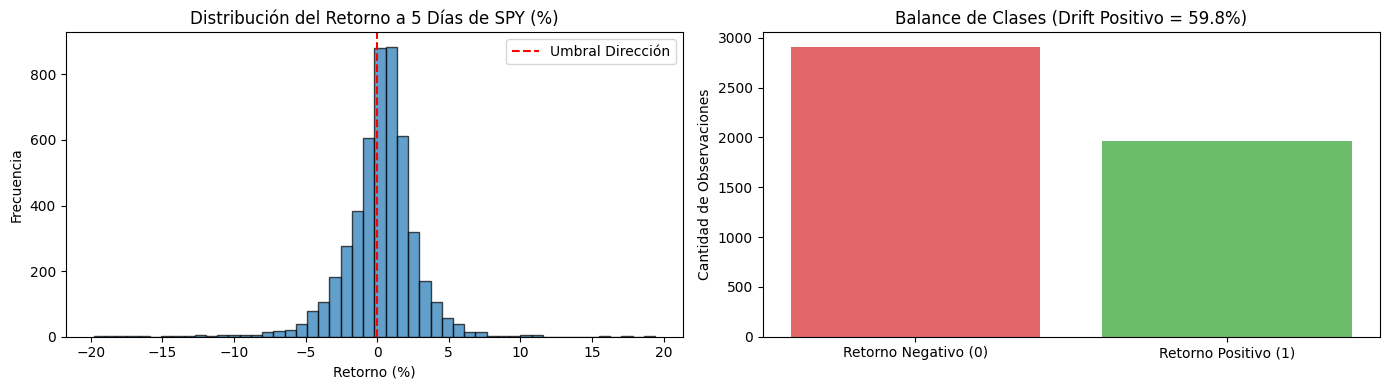

In [8]:
# ============================================================
# 8. Exploración de Datos y Estructura del Target
# ============================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].hist(dataset["future_return"] * 100, bins=50, color="#1f77b4", alpha=0.7, edgecolor="black")
ax[0].axvline(0, color="red", linestyle="--", linewidth=1.5, label="Umbral Dirección")
ax[0].set_title(f"Distribución del Retorno a {HORIZON} Días de SPY (%)")
ax[0].set_xlabel("Retorno (%)")
ax[0].set_ylabel("Frecuencia")
ax[0].legend()

counts = dataset["target"].value_counts()
ax[1].bar(["Retorno Negativo (0)", "Retorno Positivo (1)"], counts.values, color=["#d62728", "#2ca02c"], alpha=0.7)
ax[1].set_title(f"Balance de Clases (Drift Positivo = {positive_drift*100:.1f}%)")
ax[1].set_ylabel("Cantidad de Observaciones")

plt.tight_layout()
plt.show()

# 9. Protocolo de Validación Walk-Forward y Prevención de Data Leakage

### ¿Por Qué Walk-Forward y No un Split Fijo? (Feedback Docente)
En series temporales de mercados financieros, la hipótesis de estacionariedad no se cumple: la distribución de retornos y volatilidad muta continuamente debido a ciclos macroeconómicos, shocks exógenos y cambios en las tasas de interés.
Un split estático único es vulnerable al sesgo de selección del período de prueba.

Para evaluar de forma honesta y fiduciaria la capacidad de generalización del modelo, implementamos una **Validación Walk-Forward con Ventanas Expansivas (*Expanding Window Walk-Forward*)**:
1. **Fold 1 (2016 - 2018):** Train 2007-05 a 2015-12 | Test 2016-01 a 2018-12 (Ciclo inicial de suba de tasas).
2. **Fold 2 (2019 - 2021):** Train 2007-05 a 2018-12 | Test 2019-01 a 2021-12 (Guerra comercial y shock COVID-19).
3. **Fold 3 (2022 - 2024):** Train 2007-05 a 2021-12 | Test 2022-01 a 2024-12 (Shock de inflación global y endurecimiento cuantitativo).
4. **Fold 4 (2025 - 2026):** Train 2007-05 a 2024-12 | Test 2025-01 a fecha actual (Régimen Out-of-Sample reciente).

### Reglas Anticontaminación Estrictas:
1. **Purga Temporal (*Purging*):** Al finalizar cada conjunto de entrenamiento, se eliminan las últimas $H=5$ observaciones para que la etiqueta forward de 5 días no contenga retornos que solapen con el conjunto de prueba posterior.
2. **Escalado Local Exclusivo en Train:** En **cada fold de forma independiente**, el `StandardScaler` se ajusta (`fit`) **única y exclusivamente con las muestras de entrenamiento**, y se aplica (`transform`) sobre Train y Test. Jamás se ajusta el escalador sobre datos futuros.

In [9]:
# ============================================================
# 9. Especificación de Folds Walk-Forward y Funciones Utilitarias
# ============================================================
WF_FOLDS = [
    {
        "name": "Fold 1 (2016-2018)",
        "train_end": "2015-12-31",
        "test_start": "2016-01-01",
        "test_end": "2018-12-31"
    },
    {
        "name": "Fold 2 (2019-2021)",
        "train_end": "2018-12-31",
        "test_start": "2019-01-01",
        "test_end": "2021-12-31"
    },
    {
        "name": "Fold 3 (2022-2024)",
        "train_end": "2021-12-31",
        "test_start": "2022-01-01",
        "test_end": "2024-12-31"
    },
    {
        "name": "Fold 4 (2025-2026)",
        "train_end": "2024-12-31",
        "test_start": "2025-01-01",
        "test_end": None  # [FIX] hasta el último dato disponible
    }
]

feature_cols = [c for c in features.columns if c in dataset.columns]
print(f"Cantidad de features (D): {len(feature_cols)}")  # [FIX] 9 tickers x 8 + 3 cross + 3 VIX = 78

def make_sequences_from_scaled(X_scaled, y, lookback):
    Xs, ys = [], []
    for i in range(lookback - 1, len(X_scaled)):
        Xs.append(X_scaled[i - lookback + 1 : i + 1])
        ys.append(y[i])
    return np.asarray(Xs, dtype=np.float32), np.asarray(ys, dtype=np.float32)

def evaluate_predictions(y_true, probs, y_train_mean=None):
    pred = (probs >= 0.5).astype(int)
    bs = brier_score_loss(y_true, probs)
    metrics = {
        "AUC": roc_auc_score(y_true, probs) if len(np.unique(y_true)) > 1 else np.nan,
        "Accuracy": accuracy_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Brier": bs,
        # [FIX] `eps` fue eliminado de log_loss en scikit-learn >= 1.5 (TypeError). Se recorta a mano.
        "LogLoss": log_loss(y_true, np.clip(probs, 1e-7, 1 - 1e-7), labels=[0, 1]),
        "N": len(y_true)
    }
    if y_train_mean is not None:
        p_naive = np.full_like(y_true, fill_value=y_train_mean, dtype=float)
        bs_naive = brier_score_loss(y_true, p_naive)
        metrics["BSS"] = 1.0 - (bs / bs_naive)  # Brier Skill Score
    return metrics

print("Folds Walk-Forward configurados:", len(WF_FOLDS))

Cantidad de features (D): 78
Folds Walk-Forward configurados: 4


# 10. Arquitectura Deep Learning: GRU Compacta y Regularizada

Para procesar secuencias de $N = 20$ días hábiles con $D = 78$ variables estacionarias (9 activos × 8 + 3 cross-sectional + 3 del VIX), implementamos una arquitectura compacta que previene el sobreajuste precoz:

```text
[Entrada Secuencial: X_t in R^(Batch x 20 x 78)]
                   │
                   ▼
     [Inyección de Ruido Gaussiano: sigma = 0.04]
                   │
                   ▼
   [Capa Recurrente: GRU 32 Unidades con Regularización L2 1e-3]
                   │
                   ▼
   [Capa Densa de Proyección: 24 Unidades, ReLU, L2 1e-3]
                   │
                   ▼
 [Cuello de Botella Lineal: 16 Unidades -> Espacio Latente z_t]
                   │
                   ▼
      [Dropout 0.20 & LayerNormalization]
                   │
                   ▼
  [Cabeza Sigmoide: 1 Neurona -> Probabilidad Calibrada p_t]
```

In [10]:
# ============================================================
# 10. Fábrica de Modelos GRU Regularizados con Label Smoothing
# ============================================================
def build_gru_model(lookback, n_features, embed_dim=16):
    inputs = keras.Input(shape=(lookback, n_features), name="market_sequence")

    # 1. Inyección de ruido estocástico a la entrada contra memorización puntual
    x = layers.GaussianNoise(0.04, name="noise_layer")(inputs)

    # 2. Capa recurrente compacta con restricción L2 y Dropout
    x = layers.GRU(
        32,
        return_sequences=False,
        dropout=0.30,
        recurrent_dropout=0.0,
        kernel_regularizer=regularizers.l2(1e-3),
        name="gru_temporal"
    )(x)

    # 3. Proyección densa regularizada
    x = layers.Dense(
        24,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-3),
        name="dense_context"
    )(x)

    # 4. Cuello de botella latente continuo (Information Bottleneck)
    embedding = layers.Dense(
        embed_dim,
        activation="linear",
        name="market_embedding"
    )(x)

    # 5. Normalización y regularización final
    x = layers.LayerNormalization(name="embed_norm")(embedding)
    x = layers.Dropout(0.25, name="embed_dropout")(x)

    # 6. Salida probabilística sigmoide
    output = layers.Dense(1, activation="sigmoid", name="prob_output")(x)

    model = Model(inputs=inputs, outputs=output, name="AlphaTQ_GRU_Encoder")

    # Label smoothing (0.08) previene la sobreconfianza extrema en series ruidosas
    loss_fn = keras.losses.BinaryCrossentropy(label_smoothing=0.08)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1.5e-4),
        loss=loss_fn,
        metrics=["auc", "accuracy"]
    )
    return model

sample_model = build_gru_model(LOOKBACK, len(feature_cols), EMBED_DIM)
sample_model.summary()

Model: "AlphaTQ_GRU_Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ market_sequence (InputLayer)    │ (None, 20, 78)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ noise_layer (GaussianNoise)     │ (None, 20, 78)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_temporal (GRU)              │ (None, 32)             │        10,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_context (Dense)           │ (None, 24)             │           792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ market_embedding (Dense)        │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embed_norm (LayerNormalization) │ (None, 16)             │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embed_dropout (Dropout)         │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_output (Dense)             │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,993 (46.85 KB)

 Trainable params: 11,993 (46.85 KB)

 Non-trainable params: 0 (0.00 B)

# 11. Ejecución del Pipeline Walk-Forward Completo: Comparación Tripartita

En cada uno de los 4 folds se evalúan de forma estrictamente paralela los 3 enfoques:
1. **Línea de Base Ingenua (Naive):** Predice la probabilidad igual a la tasa histórica empírica de entrenamiento $\bar{y}_{train}$. No requiere features.
2. **Regresión Logística (L2):** Entrenada sobre el vector contemporáneo de variables tabulares normalizadas.
3. **Red Neuronal GRU:** Entrenada sobre los tensores secuenciales de 20 días.

En cada fold, el escalado se realiza con `StandardScaler` ajustado **única y exclusivamente con los datos de entrenamiento de ese fold**.

In [11]:
# ============================================================
# 11. Ejecución Walk-Forward: Naive vs Regresión Logística vs GRU
# ============================================================
results_by_fold = []
oos_predictions = []
last_fold_history = None
last_fold_name = None

for fold_idx, fold in enumerate(WF_FOLDS):
    print(f"\n{'='*60}\nIniciando {fold['name']}...\n{'='*60}")

    train_end = pd.Timestamp(fold["train_end"])
    test_start = pd.Timestamp(fold["test_start"])
    test_end = pd.Timestamp(fold["test_end"]) if fold["test_end"] else dataset.index.max()

    # 1. Partición de fechas con purga temporal
    train_mask = dataset.index <= train_end
    train_idx = dataset.index[train_mask]
    # Purgar las últimas H ruedas para evitar solapamiento de target
    if len(train_idx) > HORIZON:
        train_idx_purged = train_idx[:-HORIZON]
    else:
        train_idx_purged = train_idx

    test_mask = (dataset.index >= test_start) & (dataset.index <= test_end)

    df_train = dataset.loc[train_idx_purged]
    df_test = dataset.loc[test_mask]

    if len(df_test) == 0:
        continue

    print(f"Observaciones Train: {len(df_train)} | Test OOS: {len(df_test)}")

    # 2. Escalado local fold por fold (SIN LEAKAGE)
    scaler = StandardScaler()
    scaler.fit(df_train[feature_cols].values)

    X_train_raw_scaled = scaler.transform(df_train[feature_cols].values)
    y_train_raw = df_train["target"].values

    # Para evaluar el test completo con secuencias, tomamos el búfer previo de LOOKBACK-1 días
    buffer_idx = dataset.index[(dataset.index < test_start)]
    buffer_needed = buffer_idx[-(LOOKBACK - 1):] if len(buffer_idx) >= (LOOKBACK - 1) else buffer_idx
    df_test_buffered = pd.concat([dataset.loc[buffer_needed], df_test])

    X_test_buffered_scaled = scaler.transform(df_test_buffered[feature_cols].values)

    # Generar secuencias temporales para GRU
    X_train_seq, y_train_seq = make_sequences_from_scaled(X_train_raw_scaled, y_train_raw, LOOKBACK)

    # Secuencias para Test (coincidentes exactamente con las filas de df_test)
    X_test_seq, y_test_seq = make_sequences_from_scaled(X_test_buffered_scaled, df_test_buffered["target"].values, LOOKBACK)
    X_test_seq = X_test_seq[-len(df_test):]
    y_test = df_test["target"].values

    # Muestras tabulares contemporáneas (último día) para Regresión Logística
    # [FIX] BUG CRÍTICO: antes se entrenaba con datos SIN escalar y se evaluaba con datos escalados.
    X_train_tab = X_train_raw_scaled
    X_test_tab = scaler.transform(df_test[feature_cols].values)

    y_train_mean = float(y_train_raw.mean())
    print(f"Tasa base alcista en Train: {y_train_mean*100:.2f}% | Test: {y_test.mean()*100:.2f}%")

    # ------------------------------------------------------------
    # A. Modelo 0: Naive Baseline (Prior de Clase Train)
    # ------------------------------------------------------------
    p_test_naive = np.full_like(y_test, fill_value=y_train_mean, dtype=float)
    m_naive = evaluate_predictions(y_test, p_test_naive, y_train_mean)
    m_naive["Model"] = "0. Línea Base Ingenua (Naive)"
    m_naive["Fold"] = fold["name"]
    results_by_fold.append(m_naive)

    # ------------------------------------------------------------
    # B. Modelo 1: Regresión Logística (L2 Ridge)
    # ------------------------------------------------------------
    clf = LogisticRegression(C=0.5, max_iter=2000, random_state=SEED)
    clf.fit(X_train_tab, y_train_raw)
    p_test_log = clf.predict_proba(X_test_tab)[:, 1]
    m_log = evaluate_predictions(y_test, p_test_log, y_train_mean)
    m_log["Model"] = "1. Regresión Logística"
    m_log["Fold"] = fold["name"]
    results_by_fold.append(m_log)

    # ------------------------------------------------------------
    # C. Modelo 2: Red Recurrente (GRU Regularizada Anti-Colapso)
    # ------------------------------------------------------------
    gru = build_gru_model(LOOKBACK, len(feature_cols), EMBED_DIM)

    # Validación interna para EarlyStopping (últimos 15% de Train)
    # [FIX] Purga de HORIZON muestras entre train y validación: antes no existía y las
    # etiquetas a 5 días del final de X_tr solapaban con el inicio de X_va.
    val_split_len = int(len(X_train_seq) * 0.15)
    X_tr = X_train_seq[:-(val_split_len + HORIZON)]
    y_tr = y_train_seq[:-(val_split_len + HORIZON)]
    X_va = X_train_seq[-val_split_len:]
    y_va = y_train_seq[-val_split_len:]

    # Early Stopping calibrado con paciencia 2 para capturar el pico de generalización
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )

    gru_history = gru.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=10,
        batch_size=128,
        callbacks=[early_stop],
        verbose=0
    )

    last_fold_history = gru_history
    last_fold_name = fold["name"]

    p_test_gru = gru.predict(X_test_seq, verbose=0).ravel()
    m_gru = evaluate_predictions(y_test, p_test_gru, y_train_mean)
    m_gru["Model"] = "2. Deep Learning (GRU)"
    m_gru["Fold"] = fold["name"]
    results_by_fold.append(m_gru)

    # Guardar predicciones OOS
    for i, date in enumerate(df_test.index):
        oos_predictions.append({
            "Date": date,
            "Fold": fold["name"],
            "y_true": y_test[i],
            "future_return": df_test["future_return"].iloc[i],
            "next_ret1": df_test["next_ret1"].iloc[i],  # [FIX] retorno real t -> t+1
            "p_naive": p_test_naive[i],
            "p_log": p_test_log[i],
            "p_gru": p_test_gru[i]
        })

    print(f"Resultados {fold['name']} (Detenido en época {len(gru_history.history['loss'])}):")
    print(f"  Naive   -> Accuracy: {m_naive['Accuracy']:.4f} | Brier: {m_naive['Brier']:.4f}")
    print(f"  LogReg  -> Accuracy: {m_log['Accuracy']:.4f} | AUC: {m_log['AUC']:.4f} | Brier: {m_log['Brier']:.4f} | BSS: {m_log['BSS']:+.4f}")
    print(f"  GRU     -> Accuracy: {m_gru['Accuracy']:.4f} | AUC: {m_gru['AUC']:.4f} | Brier: {m_gru['Brier']:.4f} | BSS: {m_gru['BSS']:+.4f}")

df_results = pd.DataFrame(results_by_fold)
df_oos = pd.DataFrame(oos_predictions).set_index("Date")
print("\nWalk-Forward completado exitosamente.")


Iniciando Fold 1 (2016-2018)...
Observaciones Train: 2160 | Test OOS: 754
Tasa base alcista en Train: 57.36% | Test: 61.94%
Resultados Fold 1 (2016-2018) (Detenido en época 10):
  Naive   -> Accuracy: 0.6194 | Brier: 0.2378
  LogReg  -> Accuracy: 0.5517 | AUC: 0.5142 | Brier: 0.2580 | BSS: -0.0849
  GRU     -> Accuracy: 0.5875 | AUC: 0.5087 | Brier: 0.2443 | BSS: -0.0271

Iniciando Fold 2 (2019-2021)...
Observaciones Train: 2914 | Test OOS: 757
Tasa base alcista en Train: 58.41% | Test: 66.31%
Resultados Fold 2 (2019-2021) (Detenido en época 10):
  Naive   -> Accuracy: 0.6631 | Brier: 0.2296
  LogReg  -> Accuracy: 0.5112 | AUC: 0.4917 | Brier: 0.2893 | BSS: -0.2599
  GRU     -> Accuracy: 0.5918 | AUC: 0.5431 | Brier: 0.2367 | BSS: -0.0309

Iniciando Fold 3 (2022-2024)...
Observaciones Train: 3671 | Test OOS: 753
Tasa base alcista en Train: 60.09% | Test: 58.30%
Resultados Fold 3 (2022-2024) (Detenido en época 10):
  Naive   -> Accuracy: 0.5830 | Brier: 0.2434
  LogReg  -> Accuracy: 0.

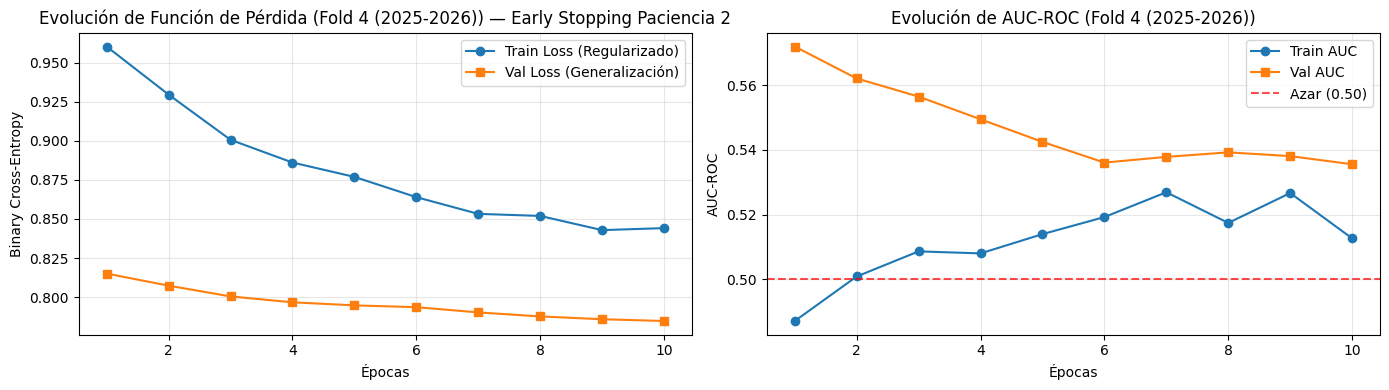

In [12]:
# ============================================================
# 11.B Visualización de Curvas de Aprendizaje (Control de Sobreajuste)
# ============================================================
if last_fold_history is not None:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))

    epochs_range = range(1, len(last_fold_history.history["loss"]) + 1)

    ax[0].plot(epochs_range, last_fold_history.history["loss"], label="Train Loss (Regularizado)", color="#1f77b4", marker="o")
    ax[0].plot(epochs_range, last_fold_history.history["val_loss"], label="Val Loss (Generalización)", color="#ff7f0e", marker="s")
    ax[0].set_title(f"Evolución de Función de Pérdida ({last_fold_name}) — Early Stopping Paciencia 2")
    ax[0].set_xlabel("Épocas")
    ax[0].set_ylabel("Binary Cross-Entropy")
    ax[0].legend()
    ax[0].grid(True, alpha=0.3)

    ax[1].plot(epochs_range, last_fold_history.history["auc"], label="Train AUC", color="#1f77b4", marker="o")
    ax[1].plot(epochs_range, last_fold_history.history["val_auc"], label="Val AUC", color="#ff7f0e", marker="s")
    ax[1].axhline(0.5, color="red", linestyle="--", alpha=0.7, label="Azar (0.50)")
    ax[1].set_title(f"Evolución de AUC-ROC ({last_fold_name})")
    ax[1].set_xlabel("Épocas")
    ax[1].set_ylabel("AUC-ROC")
    ax[1].legend()
    ax[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# 12. Consolidación de Resultados Walk-Forward y Auditoría de Métricas

Se auditan las métricas OOS para cada fold y el promedio general ponderado.
- **Brier Score:** Menor es mejor. Cuantifica el error cuadrático medio de las probabilidades: $\frac{1}{N}\sum (p_i - y_i)^2$.
- **Brier Skill Score ($BSS$):** Mide la mejora porcentual en calibración frente al Naive Baseline:
  $$BSS = 1 - \frac{BS_{modelo}}{BS_{naive}}$$
  Un valor $BSS > 0$ indica calibración genuinamente superior; un valor $BSS \le 0$ demuestra que el modelo está descalibrado.

In [13]:
# ============================================================
# 12. Tabla Consolidada Walk-Forward
# ============================================================
pivot_acc = df_results.pivot(index="Fold", columns="Model", values="Accuracy")
pivot_auc = df_results.pivot(index="Fold", columns="Model", values="AUC")
pivot_brier = df_results.pivot(index="Fold", columns="Model", values="Brier")
pivot_bss = df_results.pivot(index="Fold", columns="Model", values="BSS")

summary_table = df_results.groupby("Model").agg({
    "Accuracy": ["mean", "std"],
    "AUC": ["mean", "std"],
    "Brier": ["mean", "std"],
    "BSS": ["mean"]
}).round(4)

print("=== TABLA RESUMEN WALK-FORWARD (PROMEDIO SIMPLE ENTRE FOLDS) ===")
display(summary_table)

# [FIX] Promedio PONDERADO por cantidad de ruedas de test de cada fold
# (el informe lo rotulaba "ponderado" pero el código calculaba el promedio simple)
def weighted_summary(df):
    rows = []
    for model, g in df.groupby("Model"):
        w = g["N"] / g["N"].sum()
        rows.append({"Model": model, "N_total": int(g["N"].sum()),
                     **{m: float((g[m] * w).sum()) for m in ["Accuracy", "AUC", "Brier", "BSS"]}})
    return pd.DataFrame(rows).set_index("Model").round(4)

weighted_table = weighted_summary(df_results)
print("\n=== TABLA RESUMEN WALK-FORWARD (PROMEDIO PONDERADO POR N DE TEST) ===")
display(weighted_table)

print("\n=== BRIER SCORE POR FOLD (MENOR ES MEJOR) ===")
display(pivot_brier.round(4))

print("\n=== BRIER SKILL SCORE (BSS) POR FOLD (> 0 INDICA VENTAJA SOBRE NAIVE) ===")
display(pivot_bss.round(4))

=== TABLA RESUMEN WALK-FORWARD (PROMEDIO SIMPLE ENTRE FOLDS) ===


Accuracy             AUC           Brier  \
                                  mean     std    mean     std    mean   
Model                                                                    
0. Línea Base Ingenua (Naive)   0.6156  0.0351  0.5000  0.0000  0.2379   
1. Regresión Logística          0.5518  0.0298  0.5232  0.0274  0.2643   
2. Deep Learning (GRU)          0.5615  0.0333  0.5096  0.0271  0.2519   

                                          BSS  
                                  std    mean  
Model                                          
0. Línea Base Ingenua (Naive)  0.0060  0.0000  
1. Regresión Logística         0.0168 -0.1128  
2. Deep Learning (GRU)         0.0136 -0.0583


=== TABLA RESUMEN WALK-FORWARD (PROMEDIO PONDERADO POR N DE TEST) ===


,N_total,Accuracy,AUC,Brier,BSS
Model,,,,,
0. Línea Base Ingenua (Naive),2703,0.6178,0.5000,0.2376,0.0000
1. Regresión Logística,2703,0.5505,0.5193,0.2656,-0.1200
2. Deep Learning (GRU),2703,0.5638,0.5134,0.2508,-0.0553



=== BRIER SCORE POR FOLD (MENOR ES MEJOR) ===


Model,0. Línea Base Ingenua (Naive),1. Regresión Logística,2. Deep Learning (GRU)
Fold,,,
Fold 1 (2016-2018),0.2378,0.2580,0.2443
Fold 2 (2019-2021),0.2296,0.2893,0.2367
Fold 3 (2022-2024),0.2434,0.2566,0.2658
Fold 4 (2025-2026),0.2406,0.2532,0.2607



=== BRIER SKILL SCORE (BSS) POR FOLD (> 0 INDICA VENTAJA SOBRE NAIVE) ===


Model,0. Línea Base Ingenua (Naive),1. Regresión Logística,2. Deep Learning (GRU)
Fold,,,
Fold 1 (2016-2018),0.0,-0.0849,-0.0271
Fold 2 (2019-2021),0.0,-0.2599,-0.0309
Fold 3 (2022-2024),0.0,-0.0541,-0.0918
Fold 4 (2025-2026),0.0,-0.0522,-0.0834


# 13. Calibración Probabilística y Reliability Diagrams (Diagramas de Calibración)

Una red neuronal puede alcanzar un Accuracy aceptable pero estar completamente sobreconfiada (por ejemplo, emitiendo probabilidades de 0.90 cuando la frecuencia observada de éxito es solo del 55%). En la gestión de capital y trading fiduciario, la **sobreconfianza no calibrada es destructiva**.

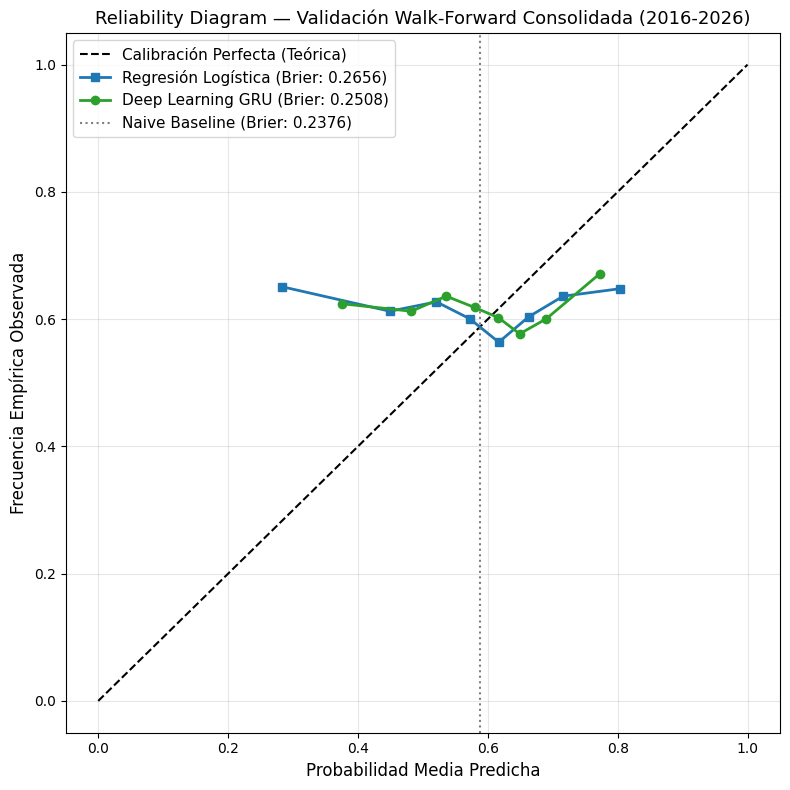

In [14]:
# ============================================================
# 13. Reliability Diagram Consolidado Out-of-Sample
# ============================================================
y_all = df_oos["y_true"].values
p_all_log = df_oos["p_log"].values
p_all_gru = df_oos["p_gru"].values

fig, ax = plt.subplots(figsize=(8, 8))

# Diagonal de calibración perfecta
ax.plot([0, 1], [0, 1], "k--", label="Calibración Perfecta (Teórica)")

# Regresión Logística
prob_true_log, prob_pred_log = calibration_curve(y_all, p_all_log, n_bins=8, strategy="quantile")
ax.plot(prob_pred_log, prob_true_log, marker="s", color="#1f77b4", linewidth=2, label=f"Regresión Logística (Brier: {brier_score_loss(y_all, p_all_log):.4f})")

# GRU Deep Learning
prob_true_gru, prob_pred_gru = calibration_curve(y_all, p_all_gru, n_bins=8, strategy="quantile")
ax.plot(prob_pred_gru, prob_true_gru, marker="o", color="#2ca02c", linewidth=2, label=f"Deep Learning GRU (Brier: {brier_score_loss(y_all, p_all_gru):.4f})")

# Naive Baseline
p_all_naive = df_oos["p_naive"].values
ax.axvline(p_all_naive.mean(), color="gray", linestyle=":", label=f"Naive Baseline (Brier: {brier_score_loss(y_all, p_all_naive):.4f})")

ax.set_xlabel("Probabilidad Media Predicha", fontsize=12)
ax.set_ylabel("Frecuencia Empírica Observada", fontsize=12)
ax.set_title("Reliability Diagram — Validación Walk-Forward Consolidada (2016-2026)", fontsize=13)
ax.legend(loc="upper left", fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 14. Caso de Estudio: ¿Por Qué la Calibración Importa para el Dimensionamiento?

En la arquitectura de **AlphaTQ**, la probabilidad estimada $p_t$ alimenta el dimensionamiento de la posición. Se comparan dos reglas (posición solo comprada, entre 0 y 1):

- **Half-Kelly real** (apuesta de pago simétrico): Kelly completo es $f = 2p - 1$; la mitad es
  $$f^{HK}_t = \text{clip}\left(p_t - 0.50,\ 0,\ 1\right)$$
- **Sizing lineal agresivo** (la regla usada en versiones previas, que **no** es Half-Kelly: equivale a 2,5 veces Kelly completo):
  $$f^{lin}_t = \text{clip}\left(\frac{p_t - 0.50}{0.20},\ 0,\ 1\right)$$

**Correcciones de esta versión:** la posición decidida al cierre de $t$ se aplica al **retorno real del día siguiente** ($t \to t+1$), no a un promedio del retorno futuro a 5 días; el Buy & Hold es el retorno diario real de SPY; y se descuentan **costos de transacción** de `TRANSACTION_COST_BPS` por unidad de rotación de la posición.


Sizing: half_kelly | Costos: 5 bps por unidad de rotación


,Retorno total,Retorno anual,Volatilidad anual,Sharpe (rf=0),Max Drawdown,Exposición media
Buy & Hold SPY,3.5834,0.1525,0.1771,0.8613,-0.3372,1.0000
Regresión Logística,0.1354,0.0119,0.0324,0.3680,-0.0802,0.1117
GRU,0.1455,0.0127,0.0201,0.6348,-0.0439,0.1056


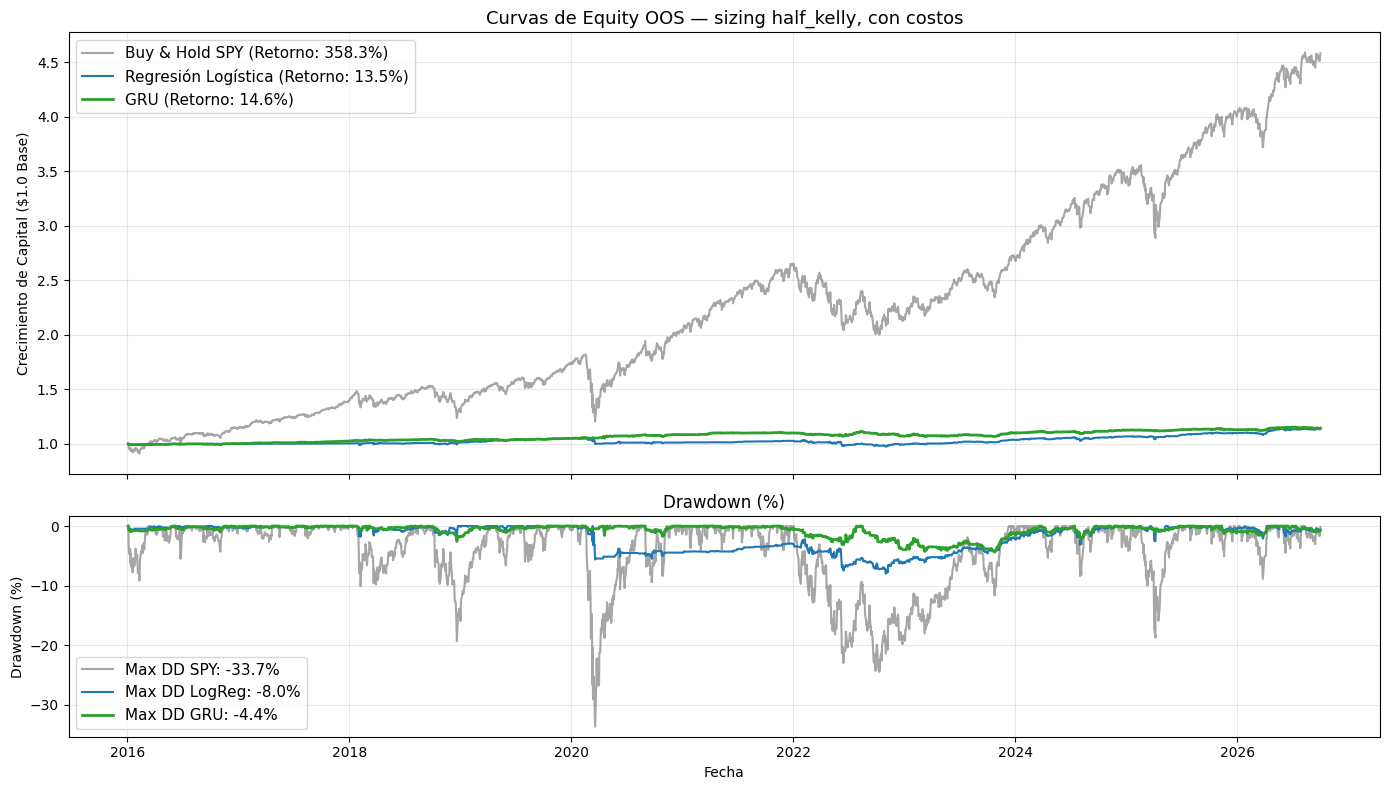

In [15]:
# ============================================================
# 14. Simulación Económica OOS (retornos diarios reales + costos)
# ============================================================
SIZING_MODE = "half_kelly"   # "half_kelly" (real) o "lineal" (regla agresiva anterior)

def position_size(p, mode=SIZING_MODE):
    if mode == "half_kelly":
        return np.clip(p - 0.50, 0, 1)
    if mode == "lineal":
        return np.clip((p - 0.50) / 0.20, 0, 1)
    raise ValueError(mode)

df_sim = df_oos.copy().sort_index()
cost = TRANSACTION_COST_BPS / 10_000

# Benchmark pasivo real: Buy & Hold SPY con retornos diarios (sin rotación, sin costos)
df_sim["ret_bh"] = df_sim["next_ret1"]

def strategy_returns(p):
    f = pd.Series(position_size(p), index=df_sim.index)
    turnover = f.diff().abs().fillna(f.abs())
    return f * df_sim["next_ret1"] - turnover * cost, f

df_sim["strat_log_ret"], df_sim["f_log"] = strategy_returns(df_sim["p_log"].values)
df_sim["strat_gru_ret"], df_sim["f_gru"] = strategy_returns(df_sim["p_gru"].values)

equity_bh = (1 + df_sim["ret_bh"]).cumprod()
equity_log = (1 + df_sim["strat_log_ret"]).cumprod()
equity_gru = (1 + df_sim["strat_gru_ret"]).cumprod()

def calc_drawdown(equity_series):
    peak = equity_series.cummax()
    return (equity_series - peak) / peak

def perf_stats(rets, equity, exposure=None):
    ann_ret = equity.iloc[-1] ** (252 / len(rets)) - 1
    ann_vol = rets.std() * np.sqrt(252)
    return {
        "Retorno total": equity.iloc[-1] - 1,
        "Retorno anual": ann_ret,
        "Volatilidad anual": ann_vol,
        "Sharpe (rf=0)": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "Max Drawdown": calc_drawdown(equity).min(),
        "Exposición media": np.nan if exposure is None else exposure.mean(),
    }

stats = pd.DataFrame({
    "Buy & Hold SPY": perf_stats(df_sim["ret_bh"], equity_bh, pd.Series(1.0, index=df_sim.index)),
    "Regresión Logística": perf_stats(df_sim["strat_log_ret"], equity_log, df_sim["f_log"]),
    "GRU": perf_stats(df_sim["strat_gru_ret"], equity_gru, df_sim["f_gru"]),
}).T
print(f"Sizing: {SIZING_MODE} | Costos: {TRANSACTION_COST_BPS} bps por unidad de rotación")
display(stats.round(4))

dd_bh, dd_log, dd_gru = calc_drawdown(equity_bh), calc_drawdown(equity_log), calc_drawdown(equity_gru)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax[0].plot(equity_bh, label=f"Buy & Hold SPY (Retorno: {(equity_bh.iloc[-1]-1)*100:.1f}%)", color="gray", alpha=0.7)
ax[0].plot(equity_log, label=f"Regresión Logística (Retorno: {(equity_log.iloc[-1]-1)*100:.1f}%)", color="#1f77b4")
ax[0].plot(equity_gru, label=f"GRU (Retorno: {(equity_gru.iloc[-1]-1)*100:.1f}%)", color="#2ca02c", linewidth=2)
ax[0].set_title(f"Curvas de Equity OOS — sizing {SIZING_MODE}, con costos", fontsize=13)
ax[0].set_ylabel("Crecimiento de Capital ($1.0 Base)")
ax[0].legend(fontsize=11)
ax[0].grid(True, alpha=0.3)

ax[1].plot(dd_bh * 100, label=f"Max DD SPY: {dd_bh.min()*100:.1f}%", color="gray", alpha=0.7)
ax[1].plot(dd_log * 100, label=f"Max DD LogReg: {dd_log.min()*100:.1f}%", color="#1f77b4")
ax[1].plot(dd_gru * 100, label=f"Max DD GRU: {dd_gru.min()*100:.1f}%", color="#2ca02c", linewidth=2)
ax[1].set_title("Drawdown (%)", fontsize=12)
ax[1].set_ylabel("Drawdown (%)")
ax[1].set_xlabel("Fecha")
ax[1].legend(fontsize=11)
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 14.B Significancia Estadística: ¿Las Diferencias Son Reales o Ruido?

Las diferencias de AUC y Brier entre modelos son pequeñas. Para saber si son distinguibles del ruido se usa un **bootstrap por bloques móviles** sobre las predicciones OOS: se remuestrean bloques contiguos de 20 ruedas (para respetar la autocorrelación que genera el solapamiento de las etiquetas a 5 días) y se calcula el intervalo de confianza del 95% de cada diferencia. Si el intervalo **contiene el 0**, la diferencia **no es estadísticamente significativa**.

In [16]:
# ============================================================
# 14.B Bootstrap por bloques: IC 95% de las diferencias OOS
# ============================================================
def block_bootstrap_ci(y, p_a, p_b, metric, block=20, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y)
    n_blocks = int(np.ceil(n / block))
    diffs = []
    for _ in range(n_boot):
        starts = rng.integers(0, n - block + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block) for s in starts])[:n]
        yb = y[idx]
        if len(np.unique(yb)) < 2:
            continue
        diffs.append(metric(yb, p_a[idx]) - metric(yb, p_b[idx]))
    diffs = np.asarray(diffs)
    return metric(y, p_a) - metric(y, p_b), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

oos_sorted = df_oos.sort_index()
y_o = oos_sorted["y_true"].values.astype(int)
p_n, p_l, p_g = (oos_sorted[c].values for c in ["p_naive", "p_log", "p_gru"])

comparisons = [
    ("AUC: GRU - LogReg (>0 favorece GRU)", roc_auc_score, p_g, p_l),
    ("Brier: GRU - LogReg (<0 favorece GRU)", brier_score_loss, p_g, p_l),
    ("Brier: GRU - Naive (<0 favorece GRU)", brier_score_loss, p_g, p_n),
    ("Brier: LogReg - Naive (<0 favorece LogReg)", brier_score_loss, p_l, p_n),
]
rows = []
for name, metric, a, b in comparisons:
    d, lo, hi = block_bootstrap_ci(y_o, a, b, metric)
    rows.append({"Comparación": name, "Diferencia": d, "IC95 inf": lo, "IC95 sup": hi,
                 "Significativa": not (lo <= 0 <= hi)})
sig_table = pd.DataFrame(rows).set_index("Comparación")
display(sig_table.round(4))


,Diferencia,IC95 inf,IC95 sup,Significativa
Comparación,,,,
AUC: GRU - LogReg (>0 favorece GRU),0.0051,-0.0365,0.0457,False
Brier: GRU - LogReg (<0 favorece GRU),-0.0148,-0.0281,-0.0026,True
Brier: GRU - Naive (<0 favorece GRU),0.0133,0.0066,0.0204,True
Brier: LogReg - Naive (<0 favorece LogReg),0.0281,0.0166,0.0410,True


# 15. Conclusiones del Experimento y Respuesta a la Pregunta Científica

> **¿Puede una red neuronal recurrente (GRU) predecir el signo del retorno de SPY a 5 días superando a la Regresión Logística y al Naive Baseline bajo validación Walk-Forward y calibración de Brier?**

Los valores de esta sección **se calculan en la celda siguiente** a partir de los resultados reales de esta ejecución; no hay cifras escritas a mano. Al interpretarlas:

1. **Frente a la Línea de Base Ingenua:** el drift alcista de SPY hace que predecir siempre la tasa histórica sea un rival muy difícil en Accuracy y Brier. Un $BSS \le 0$ significa que el modelo no aporta calibración por encima de esa constante.
2. **Frente a la Regresión Logística:** solo se puede afirmar que la GRU es mejor si el intervalo de confianza del bootstrap (sección 14.B) **no contiene el 0**.
3. **Implicancia para AlphaTQ:** si ningún modelo supera de forma significativa al Naive, la red no debe usarse como señal direccional autónoma; su eventual rol como sensor de contexto en la Capa 1 queda como hipótesis a validar en trabajos futuros (este notebook no analiza el espacio latente $z_t$).


In [17]:
# ============================================================
# 15.B Conclusiones generadas desde los resultados de esta ejecución
# ============================================================
wt = weighted_table
naive, lr, gru = "0. Línea Base Ingenua (Naive)", "1. Regresión Logística", "2. Deep Learning (GRU)"

print(f"Drift positivo de SPY en todo el dataset: {positive_drift*100:.1f}%")
print(f"Ruedas OOS evaluadas: {int(wt.loc[naive, 'N_total'])}\n")
for m in [naive, lr, gru]:
    print(f"{m:35s} Acc {wt.loc[m,'Accuracy']*100:5.2f}% | AUC {wt.loc[m,'AUC']:.4f} | "
          f"Brier {wt.loc[m,'Brier']:.4f} | BSS {wt.loc[m,'BSS']*100:+.2f}%")

print()
for name, r in sig_table.iterrows():
    veredicto = "SIGNIFICATIVA" if r["Significativa"] else "no significativa (el IC contiene 0)"
    print(f"{name}: {r['Diferencia']:+.4f}  IC95 [{r['IC95 inf']:+.4f}, {r['IC95 sup']:+.4f}] -> {veredicto}")

print()
print("Veredicto vs Naive (Brier):",
      "la GRU SUPERA al Naive" if wt.loc[gru, "BSS"] > 0 and sig_table.iloc[2]["Significativa"]
      else "la GRU NO supera al Naive")
print("Veredicto vs LogReg (AUC):",
      ("la GRU supera a la LogReg" if sig_table.iloc[0]["Diferencia"] > 0 else "la LogReg supera a la GRU")
      if sig_table.iloc[0]["Significativa"] else "sin diferencia significativa entre GRU y LogReg")


Drift positivo de SPY en todo el dataset: 59.8%
Ruedas OOS evaluadas: 2703

0. Línea Base Ingenua (Naive)       Acc 61.78% | AUC 0.5000 | Brier 0.2376 | BSS +0.00%
1. Regresión Logística              Acc 55.05% | AUC 0.5193 | Brier 0.2656 | BSS -12.00%
2. Deep Learning (GRU)              Acc 56.38% | AUC 0.5134 | Brier 0.2508 | BSS -5.53%

AUC: GRU - LogReg (>0 favorece GRU): +0.0051  IC95 [-0.0365, +0.0457] -> no significativa (el IC contiene 0)
Brier: GRU - LogReg (<0 favorece GRU): -0.0148  IC95 [-0.0281, -0.0026] -> SIGNIFICATIVA
Brier: GRU - Naive (<0 favorece GRU): +0.0133  IC95 [+0.0066, +0.0204] -> SIGNIFICATIVA
Brier: LogReg - Naive (<0 favorece LogReg): +0.0281  IC95 [+0.0166, +0.0410] -> SIGNIFICATIVA

Veredicto vs Naive (Brier): la GRU NO supera al Naive
Veredicto vs LogReg (AUC): sin diferencia significativa entre GRU y LogReg


In [18]:
# ============================================================
# 16. Manifest de Reproducibilidad Institucional
# ============================================================
manifest = {
    "institucion": "Universidad de Palermo - Maestria en IA",
    "materia": "Redes Neuronales y Deep Learning",
    "target": TARGET,
    "universo": TICKERS,
    "periodo_comun_inicio": START,
    "horizonte_ruedas": HORIZON,
    "lookback_ruedas": LOOKBACK,
    "semilla": SEED,
    "protocolo": "Expanding Window Walk-Forward",
    "folds_evaluados": len(WF_FOLDS),
    "total_observaciones": len(dataset),
    "drift_positivo_spy": float(positive_drift),
    "n_features": len(feature_cols),
    "sizing": SIZING_MODE,
    "costos_bps": TRANSACTION_COST_BPS,
    "versiones": {"tensorflow": tf.__version__, "sklearn": __import__("sklearn").__version__,
                  "pandas": pd.__version__, "numpy": np.__version__, "yfinance": yf.__version__}
}

print(json.dumps(manifest, indent=2))
with open("reproducibility_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)
print("Manifest guardado exitosamente.")

{
  "institucion": "Universidad de Palermo - Maestria en IA",
  "materia": "Redes Neuronales y Deep Learning",
  "target": "SPY",
  "universo": [
    "GLD",
    "HYG",
    "IWM",
    "QQQ",
    "SPY",
    "TLT",
    "USO",
    "XLE",
    "XLK"
  ],
  "periodo_comun_inicio": "2007-05-01",
  "horizonte_ruedas": 5,
  "lookback_ruedas": 20,
  "semilla": 42,
  "protocolo": "Expanding Window Walk-Forward",
  "folds_evaluados": 4,
  "total_observaciones": 4868,
  "drift_positivo_spy": 0.5975760065735415,
  "n_features": 78,
  "sizing": "half_kelly",
  "costos_bps": 5,
  "versiones": {
    "tensorflow": "2.21.0",
    "sklearn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.1.3",
    "yfinance": "0.2.66"
  }
}
Manifest guardado exitosamente.
